# Module 2 — Discounting the far future: four methods, calibrated to data

**Project:** *Pricing the Future*, an empirical extension of my M.Sc. project (University of Bath).

**Why discounting decides climate policy.** Climate damages arrive over centuries, so the social cost of carbon (SCC) is a present value dominated by distant years. At 1% a year, \$1 of damage in 300 years is worth about 5¢ today; at 4% it is worth less than a hundredth of a cent. **The choice of discounting method can move the SCC by an order of magnitude, more than any damage estimate.**

**What the original paper did.** It compared fixed, Weitzman (gamma), stochastic (Newell–Pizer) and stochastic-discount-factor (SDF) discounting using **assumed** parameters.

**What this notebook does.** It **estimates** each method's parameters from data:

| Method | Key idea | Parameters estimated from |
|---|---|---|
| Constant | One rate forever | Average US real long-term rate, 1953–present |
| Gamma (Weitzman 2001) | The "true" rate is unknown; average the discount *factors* | Weitzman's survey of 2,160 economists; US real-rate history |
| Newell–Pizer (2003) | Rates follow a persistent random process | Persistence and volatility of US 10-year yields (FRED) |
| Consumption SDF (Ramsey) | Discount by the marginal utility of future consumption | Mean, volatility and estimation error of world GDP-per-capita growth (Module 1 panel) |

All computation lives in the tested Python package `python/climate_discount/` (run `pytest python/tests` to check it). This notebook runs it and explains the results.

In [1]:
# --- Setup -------------------------------------------------------------------
import sys, os
from pathlib import Path

# Move to the repo root so data paths resolve, and make the package importable
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd() / "python"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

import run_discounting as rd          # the Step 3 script, used as a module
pd.options.display.float_format = "{:,.2f}".format

# Calibrate from the data, build every schedule, save tables and figures
res = rd.main()
cal, S, summary = res["cal"], res["schedules"], res["summary"]


================ STEP 3 KEY RESULTS ================
US real rate 1953-2025: mean 2.01%, std 2.35%
Log US 10y yield AR(1): phi = 0.924 (se 0.044), sigma = 0.203; RW sigma = 0.206
Log Canada 10y yield AR(1): phi = 0.950, sigma = 0.200
World GDP pc growth 1961-2025: mean 2.35%, std 1.59%, se(mean) 0.20%

                                 method  fwd rate yr 1 (%)  fwd rate yr 100 (%)  fwd rate yr 300 (%)  CE rate to yr 300 (%)  $1M in 100 yrs, today ($)  $1M in 300 yrs, today ($)  PV of $1/yr for 300 yrs ($)
     Constant 2.0% (US mean real rate)               2.01                 2.01                 2.01                   2.01                 133,896.31                   2,400.52                        49.12
               Gamma (Weitzman survey)               3.92                 1.25                 0.53                   1.22                 122,404.99                  25,549.34                        44.93
          Gamma (US real-rate history)               1.98                 0.

## 1. The common language: discount factors, CE rates and forward rates

Every method produces a **discount factor** $DF(t)$, the value today of \$1 in year $t$. Two rates summarise it:

- **Certainty-equivalent (CE) rate** $R(t) = -\ln DF(t)/t$: the single constant rate that would give the same value at horizon $t$.
- **Forward rate** $f(t) = \ln DF(t-1) - \ln DF(t)$: the rate applied *between* year $t-1$ and $t$. "Declining discount rates" means $f(t)$ falls with $t$.

**Why uncertainty lowers long-run rates.** If the rate is uncertain, the right discount factor is the *average of the discount factors*, $E[e^{-rt}]$, not $e^{-E[r]\,t}$. By Jensen's inequality the first is larger. At long horizons it is dominated by the low-rate scenarios, because a high-rate world discounts the future to nothing, while a low-rate world still cares about it. So the effective rate drifts towards the lowest plausible rate.

In [2]:
# A two-scenario example makes the idea concrete:
# the rate is either 1% or 5% with equal probability (mean 3%).
for t in (10, 100, 300):
    df_avg = 0.5 * np.exp(-0.01 * t) + 0.5 * np.exp(-0.05 * t)   # average of DFs
    df_mean_rate = np.exp(-0.03 * t)                              # DF at the mean rate
    print(f"t={t:>3}:  E[DF] = {df_avg:.4f}  vs  DF(mean rate) = {df_mean_rate:.4f}"
          f"   -> CE rate {-np.log(df_avg)/t:.2%}")

t= 10:  E[DF] = 0.7557  vs  DF(mean rate) = 0.7408   -> CE rate 2.80%
t=100:  E[DF] = 0.1873  vs  DF(mean rate) = 0.0498   -> CE rate 1.67%
t=300:  E[DF] = 0.0249  vs  DF(mean rate) = 0.0001   -> CE rate 1.23%


## 2. Calibration: what the data say

### Newell–Pizer: how persistent are interest rates?

Following Newell & Pizer (2003), we model the log of the long-term government bond yield as an AR(1):

$$x_t = a + \phi\, x_{t-1} + \varepsilon_t, \qquad x_t = \ln r_t$$

$\phi$ measures persistence. Close to 1 means shocks to rates are close to permanent, and **persistence is what produces declining long-run rates**: a temporary shock averages out, while a permanent one compounds. We take the uncertainty structure ($\phi$, $\sigma$) from the data and apply it to a real starting rate $r_0$. The simulated paths are mean-corrected so the *average* rate stays at $r_0$ in every year, which isolates the pure uncertainty effect.

In [3]:
np_us, np_ca, r0 = cal["newell_pizer"]["US"], cal["newell_pizer"]["Canada"], cal["r0"]
pd.DataFrame({
    "US":     [np_us["phi"], np_us["phi_se"], np_us["sigma_ar1"], np_us["sigma_rw"], f'{np_us["years"][0]}-{np_us["years"][1]}'],
    "Canada": [np_ca["phi"], np_ca["phi_se"], np_ca["sigma_ar1"], np_ca["sigma_rw"], f'{np_ca["years"][0]}-{np_ca["years"][1]}'],
}, index=["φ (persistence)", "se(φ)", "σ AR(1) residual", "σ random walk", "sample"])

,US,Canada
φ (persistence),0.92,0.95
se(φ),0.04,0.04
σ AR(1) residual,0.20,0.20
σ random walk,0.21,0.20
sample,1953-2025,1955-2025


In [4]:
print(f"Starting real rate r0 = mean US ex-post real 10y rate, "
      f"{r0['years'][0]}-{r0['years'][1]}: {r0['us_mean_real_rate']:.2%} "
      f"(std {r0['us_real_rate_std']:.2%})")
if r0.get("latest_tips10") is not None:
    print(f"For reference, latest 10-year TIPS real yield: {r0['latest_tips10']:.2%}")

# Is phi statistically different from 1 (a random walk)?
t_stat = (np_us["phi"] - 1) / np_us["phi_se"]
print(f"\nt-stat for φ = 1: {t_stat:.2f}  (note: under a unit root this t-stat is not "
      "normal; Dickey-Fuller critical value ≈ -2.9 at 5%)")

Starting real rate r0 = mean US ex-post real 10y rate, 1953-2025: 2.01% (std 2.35%)
For reference, latest 10-year TIPS real yield: 1.96%

t-stat for φ = 1: -1.73  (note: under a unit root this t-stat is not normal; Dickey-Fuller critical value ≈ -2.9 at 5%)


### Ramsey SDF: growth and ethics

The consumption-based discount rate follows the **Ramsey rule under uncertainty**:

$$r = \underbrace{\rho}_{\text{impatience}} + \underbrace{\eta\,\mu_g}_{\text{we'll be richer}} - \underbrace{\tfrac12\eta^2\sigma_g^2}_{\text{precautionary saving}}$$

- $\mu_g$ and $\sigma_g$ (mean and volatility of growth) **come from the data**: population-weighted world GDP-per-capita growth from the Module 1 panel.
- **Uncertainty about $\mu_g$ itself** (its standard error) adds a term that makes the forward rate decline linearly with $t$ (Gollier 2008).
- $\rho$ (pure time preference) and $\eta$ (aversion to inequality across generations) are **value judgements**, not data. We report the two classic positions: Stern (ρ = 0.1%, η = 1) and Nordhaus (ρ = 1.5%, η = 1.45).
- **Climate beta.** If damages are larger when the economy is richer (β > 0), they are riskier in the asset-pricing sense and earn a premium $\eta\beta\sigma_g^2$ (Dietz, Gollier & Kessler 2018). Module 4 tests this empirically with equity returns.

In [5]:
g = cal["growth"]
print(f"World GDP-per-capita growth {g['years'][0]}-{g['years'][1]}: "
      f"mean {g['mu_g']:.2%}, volatility {g['sigma_g']:.2%}, se of the mean {g['se_mu']:.2%}\n")
for key in ("Ramsey SDF (Stern)", "Ramsey SDF", "Ramsey SDF (β=1)"):
    p = S[key].params
    print(f"{S[key].name:<42} risk-free rate {p['risk_free_rate']:.2%}, "
          f"precautionary term {0.5 * p['eta']**2 * p['sigma_g']**2:.3%}")

World GDP-per-capita growth 1961-2025: mean 2.35%, volatility 1.59%, se of the mean 0.20%

Ramsey SDF, Stern ethics                   risk-free rate 2.43%, precautionary term 0.013%
Ramsey SDF, Nordhaus ethics                risk-free rate 4.87%, precautionary term 0.027%
Ramsey SDF, Nordhaus, climate beta = 1     risk-free rate 4.87%, precautionary term 0.027%


## 3. The term structure of discount rates

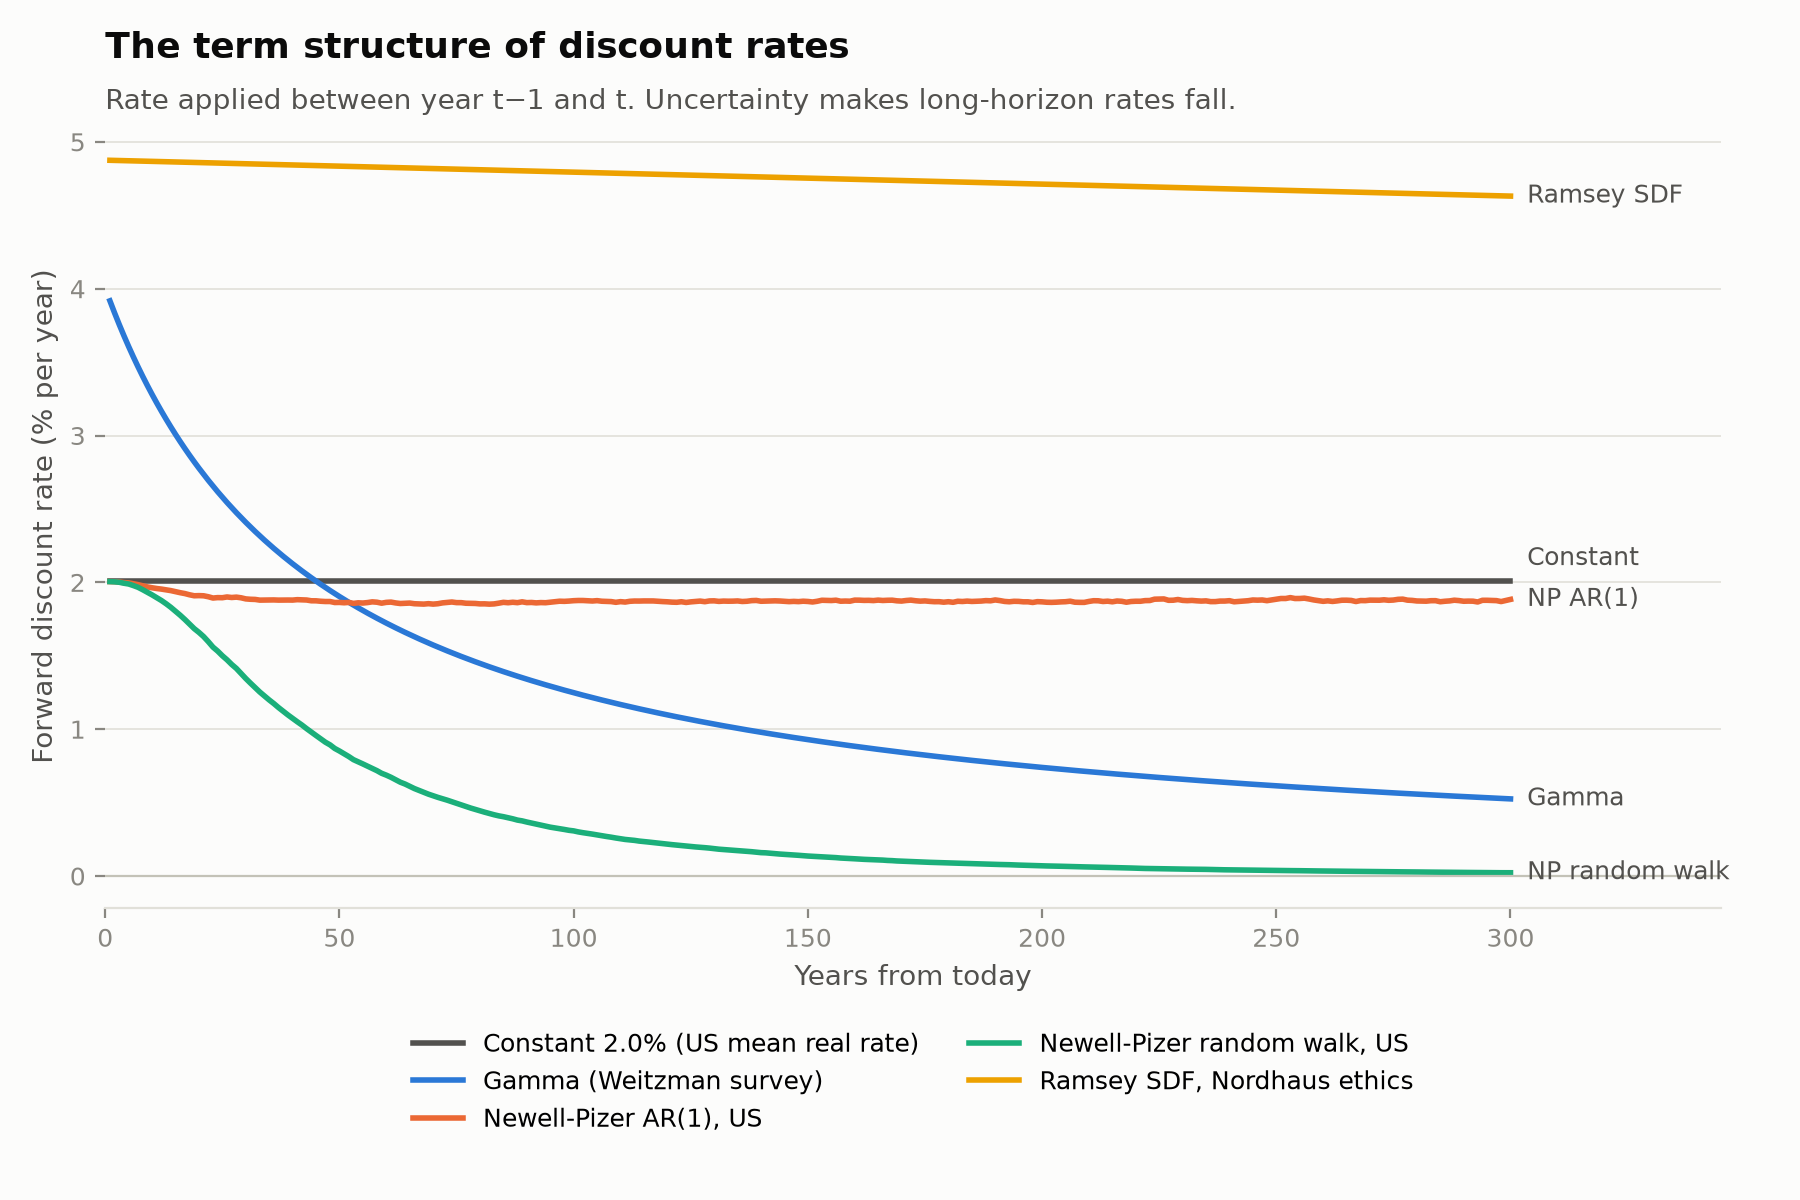

In [6]:
display(Image("output/figures/fig4_forward_rates.png", width=850))

**How to read it.** A flat line means the method discounts year 300 exactly like year 1. A falling line means distant damages get more weight than a constant rate would give them. The *level* of each line (set mostly by the starting rate or the ethical parameters) and its *slope* (set by uncertainty and persistence) are separate questions. The original paper's point was about the slope. The level matters at least as much.

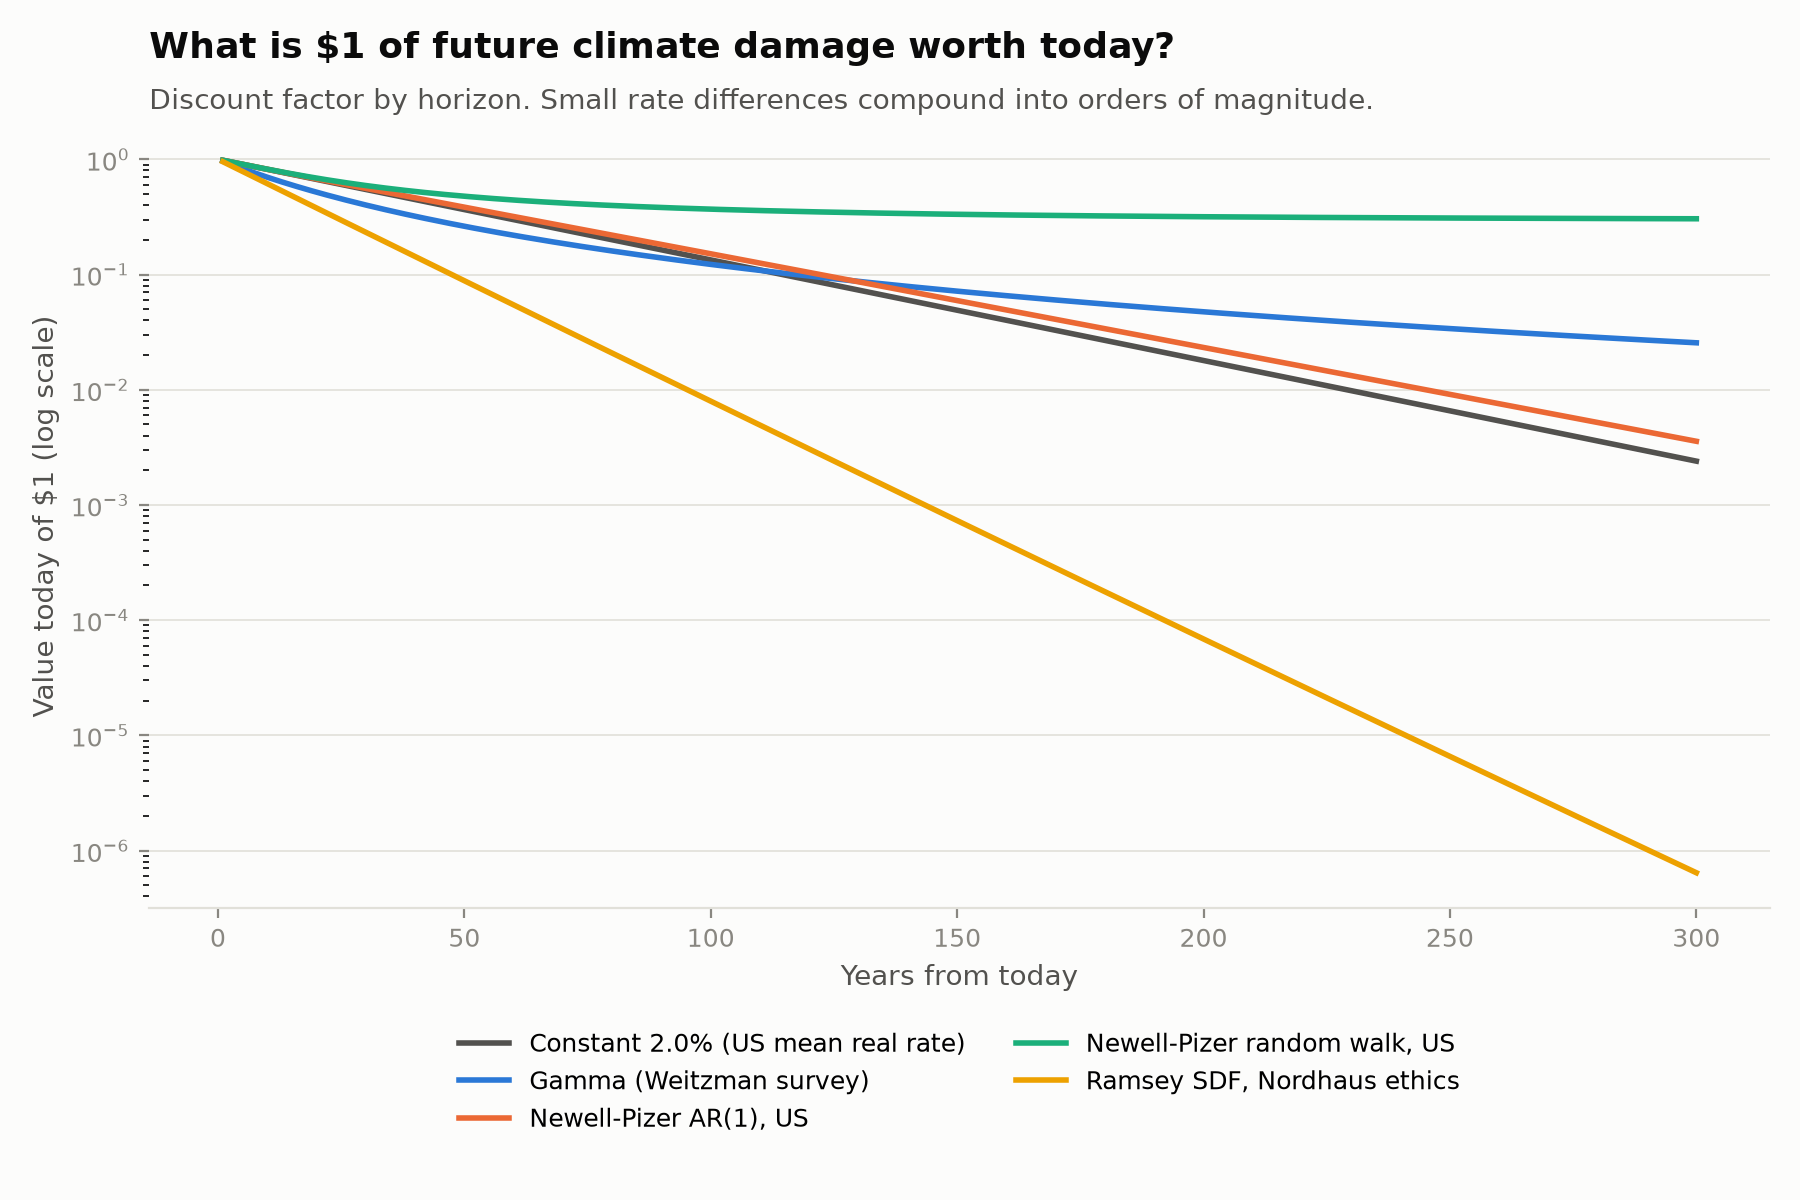

In [7]:
display(Image("output/figures/fig5_value_of_future_dollar.png", width=850))

## 4. Headline comparison

In [8]:
summary.set_index("method")

,fwd rate yr 1 (%),fwd rate yr 100 (%),fwd rate yr 300 (%),CE rate to yr 300 (%),"$1M in 100 yrs, today ($)","$1M in 300 yrs, today ($)",PV of $1/yr for 300 yrs ($)
method,,,,,,,
Constant 2.0% (US mean real rate),2.01,2.01,2.01,2.01,"133,896.31","2,400.52",49.12
Gamma (Weitzman survey),3.92,1.25,0.53,1.22,"122,404.99","25,549.34",44.93
Gamma (US real-rate history),1.98,0.54,0.22,0.54,"379,653.46","195,680.18",110.10
"Newell-Pizer AR(1), US",2.01,1.88,1.88,1.88,"151,422.89","3,570.24",51.88
"Newell-Pizer random walk, US",2.01,0.31,0.02,0.40,"369,133.98","304,680.35",118.37
"Ramsey SDF, Nordhaus ethics",4.87,4.79,4.63,4.75,"7,954.29",0.64,20.09
"Ramsey SDF, Stern ethics",2.43,2.39,2.32,2.37,"89,479.79",804.85,40.84
"Ramsey SDF, Nordhaus, climate beta = 1",4.91,4.94,5.00,4.96,"7,249.27",0.35,19.84


In [9]:
# How much does the method matter? Ratio of highest to lowest PV of a 300-year stream
pv = summary.set_index("method")["PV of $1/yr for 300 yrs ($)"]
print(f"PV of $1 a year for 300 years ranges from ${pv.min():,.2f} ({pv.idxmin()}) "
      f"to ${pv.max():,.2f} ({pv.idxmax()}): a factor of {pv.max()/pv.min():.1f}x.")

PV of $1 a year for 300 years ranges from $19.84 (Ramsey SDF, Nordhaus, climate beta = 1) to $118.37 (Newell-Pizer random walk, US): a factor of 6.0x.


## 5. Takeaways and hand-off to Module 3

**1. Whether interest-rate shocks are permanent is the single most important question, and the data cannot answer it.** Log US 10-year yields have persistence φ = 0.92 (se 0.044). The test against a random walk (t ≈ −1.7) is far from the Dickey–Fuller critical value (≈ −2.9), so we cannot reject that rate shocks are permanent. Canada is even more persistent (φ = 0.95). The two Newell–Pizer versions, both consistent with the data, imply very different futures:
- **Mean-reverting AR(1):** the forward rate barely moves (2.0% → 1.9%).
- **Random walk:** it collapses to 0.3% by year 100 and ≈ 0% by year 300.
- \$1M of damage in 300 years is worth **\$3,600** today under the first and **\$305,000** under the second, a factor of 85.

**2. Uncertainty about the *level* of the rate also produces strongly declining rates.** Gamma discounting with Weitzman's survey (μ = 3.96%, σ = 2.94%) falls from 3.9% to 0.5% by year 300. Calibrated to US real-rate history (μ = 2.0%, σ = 2.35%) it falls to 0.2%. *Caveat:* ex-post real rates include inflation surprises, so their volatility overstates uncertainty about the *expected* real rate; this calibration is an upper bound on the effect.

**3. Ethics sets the level; uncertainty sets the slope.** With growth estimated from the data (2.35% a year, volatility 1.6%), the Ramsey rule gives **2.4% under Stern** (ρ = 0.1%, η = 1) and **4.9% under Nordhaus** (ρ = 1.5%, η = 1.45). That gap is a value judgement, not an empirical one, and it alone changes the value of \$1M in 100 years from \$89,000 to \$8,000. Growth-rate uncertainty makes the SDF rates decline by only 0.1–0.25 pp over 300 years, because the long-run mean growth rate is estimated quite precisely.

**4. Consumption risk barely matters, which is the equity premium puzzle in miniature.** A climate beta of 1 adds a risk premium of ηβσ² ≈ 0.04 pp. Consumption is too smooth for the standard model to generate meaningful risk premia. Module 4 asks whether *markets* price temperature risk more heavily than this model implies.

**5. The method moves present values by a factor of ~6.** \$1 a year for 300 years is worth between **\$20** (Nordhaus SDF) and **\$118** (Newell–Pizer random walk). Since the social cost of carbon is a present value of long-dated damages, this spread carries straight through to the SCC.

**Hand-off to Module 3.** `output/tables/discount_schedules.csv` holds DF(t), year 0–400, for every method. Module 3 combines these with the Module 1 damage function and a warming scenario to compute the social cost of carbon under each one.